# Mini-Task 9 — Background Classification & VAD on VOiCES

**Course:** Digital Speech Processing — Dr. Khalooei  
**Student:** Ghassan Alsafar — **ID:** 404131085

Run **Run → Run All Cells**. The whole pipeline lives in `voices_background_vad.py`; this notebook runs it and shows the results.

Data: the official VOiCES subset (`Lab41/VOiCES-subset`). The script downloads it, or uses `VOiCES_90_*.tar` files already in `data/` or in your Downloads folder.

## 1. Run the whole experiment

In [1]:
%run voices_background_vad.py

[1/6] VOiCES data
  226 recordings available: none=63, babb=49, musi=66, tele=48
  using 48 recordings per background -> 192 recordings
[2/6] Features
  192 clips, 84 features, 74 speakers
  saved figures/fig01_background_examples.png
  saved figures/fig02_dataset_balance.png
[3/6] Part A - background classification (5-fold CV grouped by speaker)
  SVM (RBF)                82.8% ± 3.9
  Neural Network (MLP)     77.6% ± 3.3
  KNN (k=5)                61.0% ± 9.9
  Random Forest            77.1% ± 8.6
  Logistic Regression      74.4% ± 4.1
  Naive Bayes              69.3% ± 7.5
  saved figures/fig03_background_model_comparison.png
  saved figures/fig04_background_confusion.png
  saved figures/fig05_feature_importance.png
[4/6] Part B - reference speech labels (quiet recording + alignment)
  aligned 93/93 noisy recordings; 141 recordings have reference labels
[5/6] Part B - VAD comparison on held-out speakers
  Silero VAD not used (RuntimeError) - optional, needs PyTorch
  Energy VAD     

## 2. Figures

**fig01_background_examples**

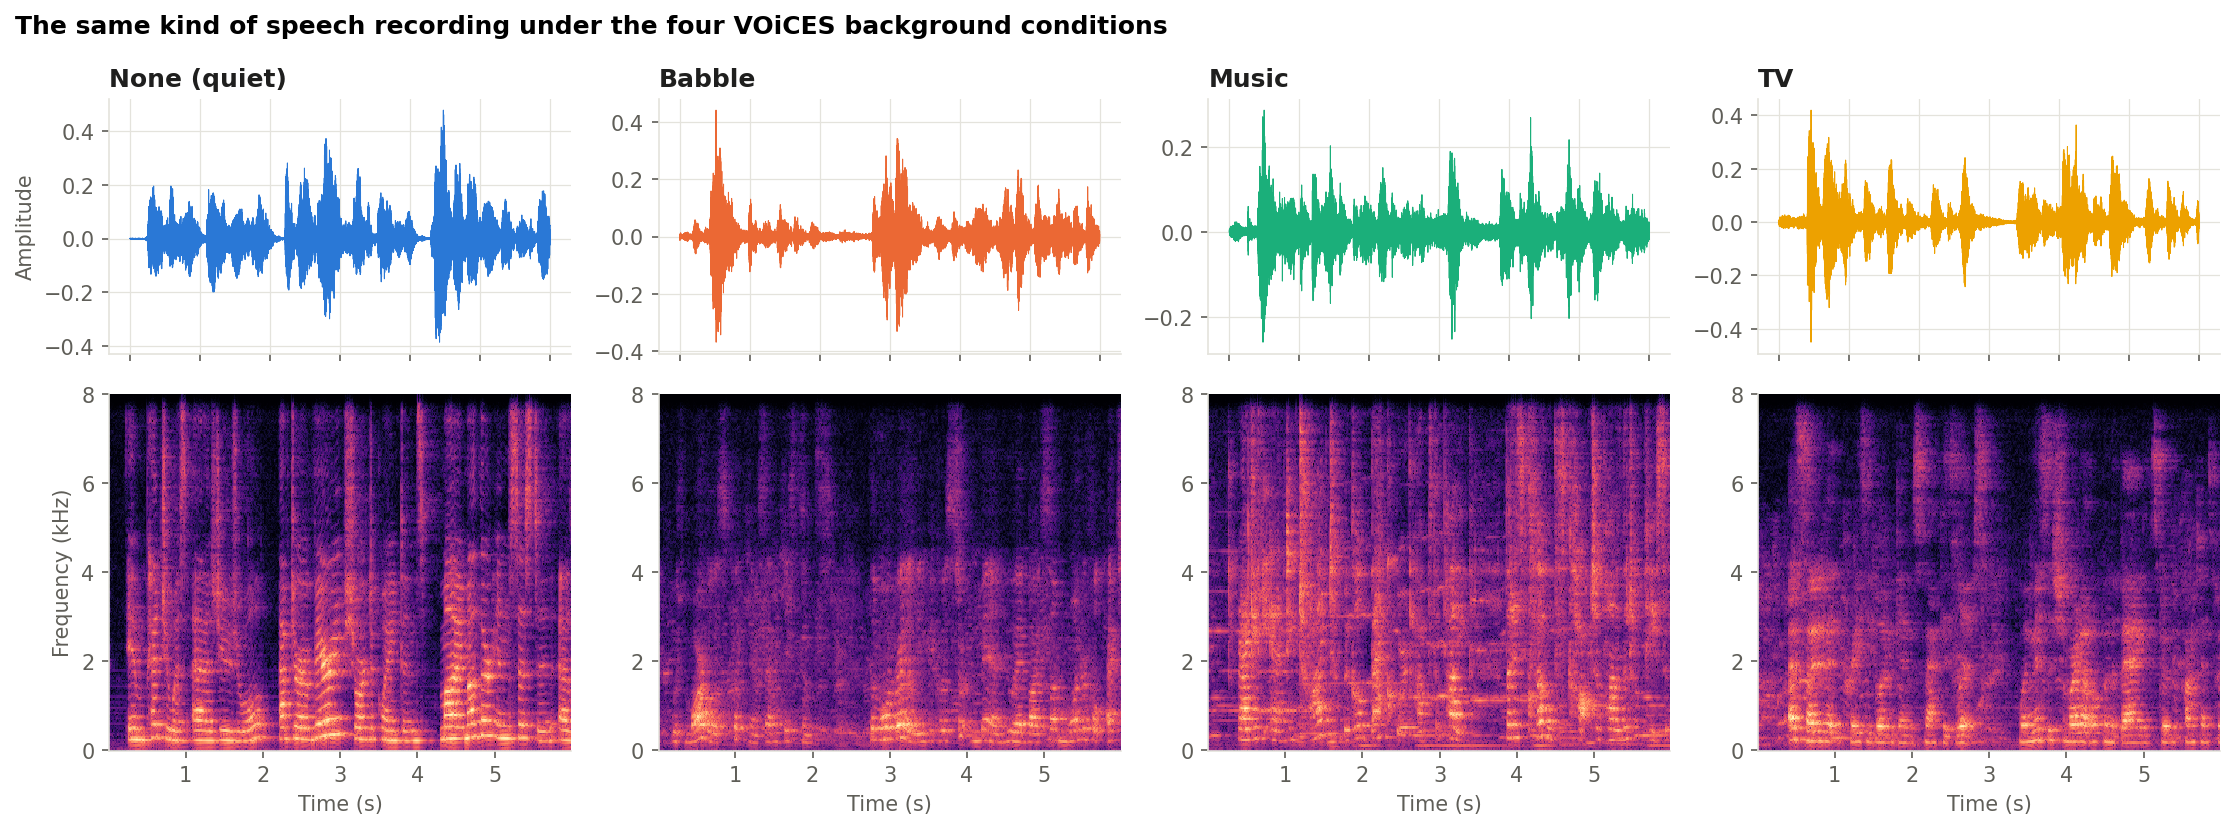

**fig02_dataset_balance**

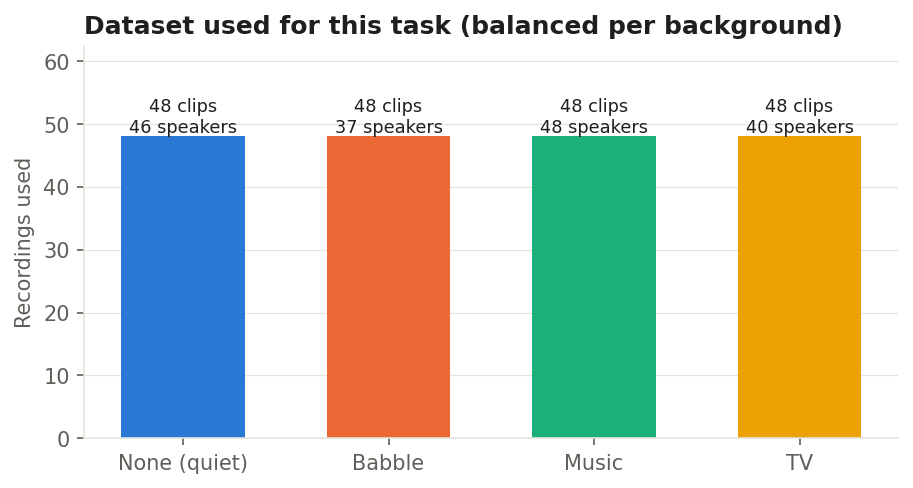

**fig03_background_model_comparison**

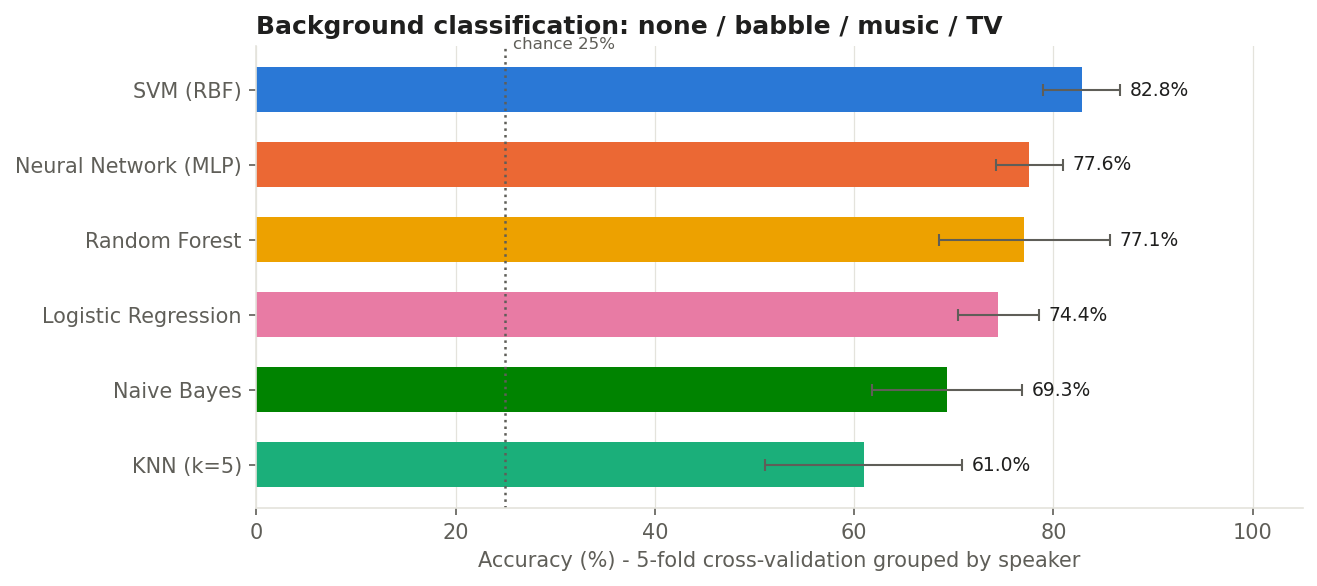

**fig04_background_confusion**

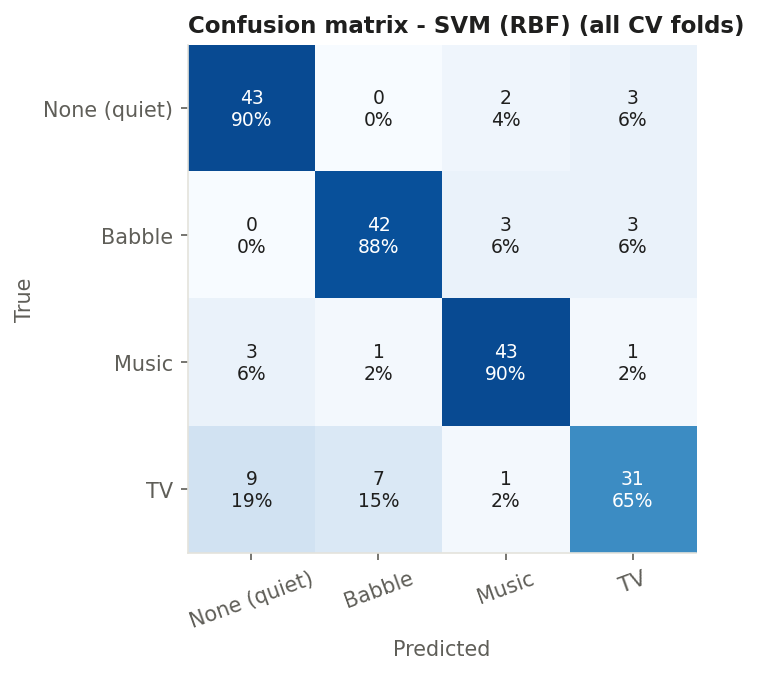

**fig05_feature_importance**

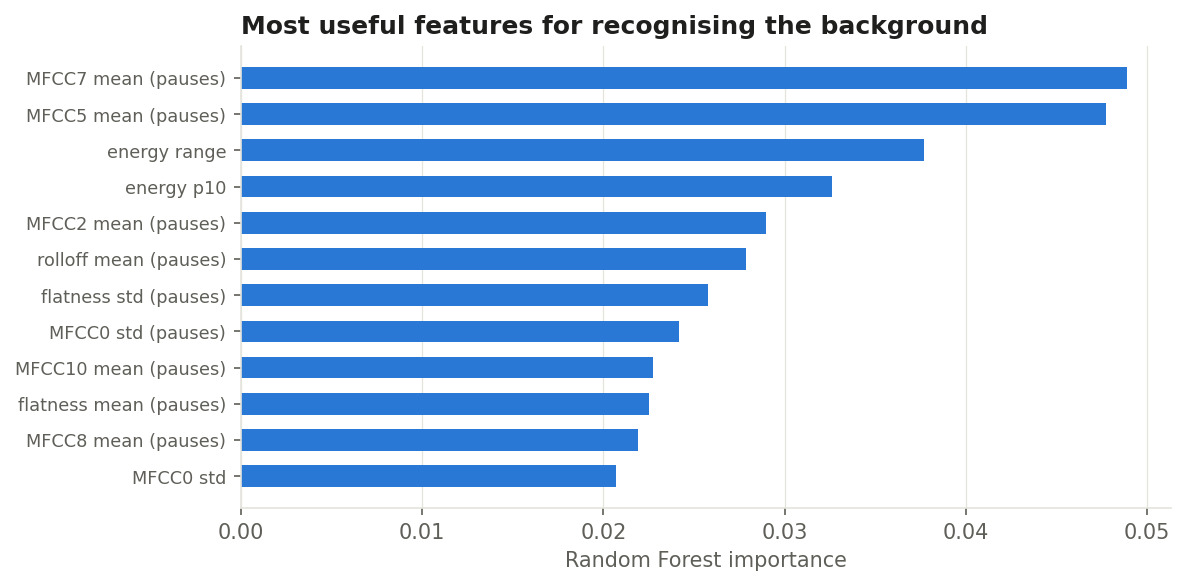

**fig06_vad_example**

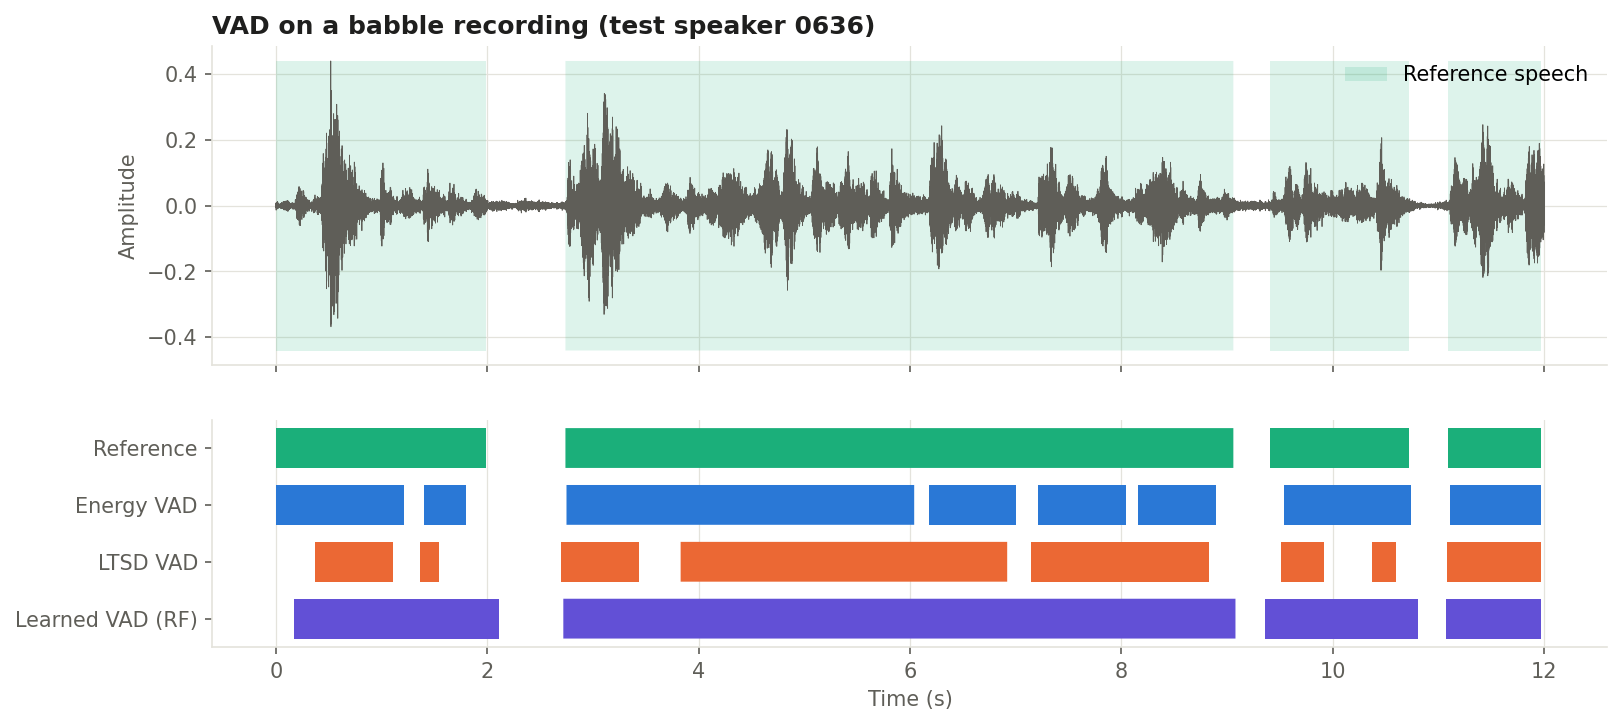

**fig07_vad_f1_by_background**

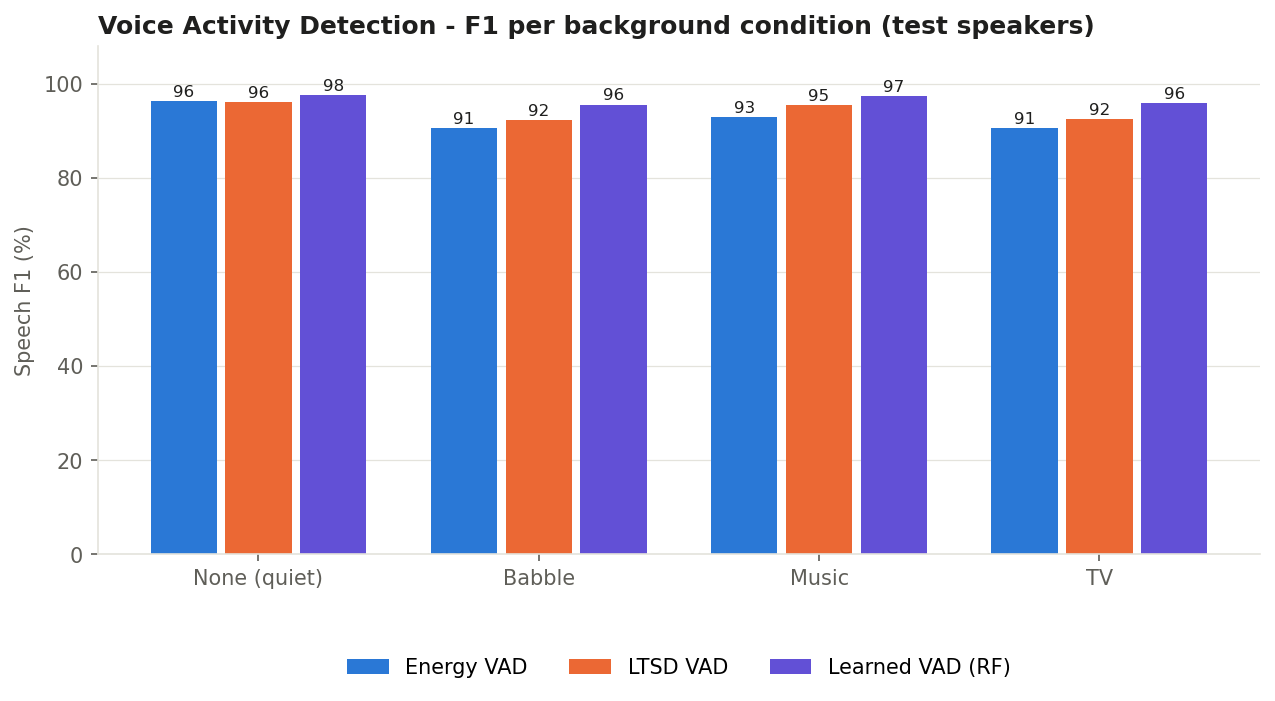

In [2]:
from pathlib import Path
from IPython.display import Image, display, Markdown
for f in sorted(Path('figures').glob('*.png')):
    display(Markdown(f'**{f.stem}**'))
    display(Image(filename=str(f)))

## 3. Results tables

In [3]:
import json, pandas as pd
r = json.load(open('results/results.json'))
cv = pd.DataFrame(r['cv']).T[['acc_mean','acc_std','f1_mean']].astype(float) * 100
display(Markdown('**Background classification** (%, 5-fold CV grouped by speaker)'))
display(cv.round(1).rename(columns={'acc_mean':'Accuracy %','acc_std':'± std','f1_mean':'Macro-F1 %'}))
vad = pd.DataFrame({m: {c: r['vad'][m][c]['f1'] * 100 for c in ['none','babb','musi','tele','all']} for m in r['vad_methods']}).T
display(Markdown(f"**VAD speech F1 (%) per background** — reference labels: {r.get('ref_mode')}, aligned {r['alignment']['ok']}/{r['alignment']['tried']}"))
display(vad.round(1))

**Background classification** (%, 5-fold CV grouped by speaker)

,Accuracy %,± std,Macro-F1 %
SVM (RBF),82.8,3.9,82.6
Neural Network (MLP),77.6,3.3,77.1
KNN (k=5),61.0,9.9,59.3
Random Forest,77.1,8.6,76.6
Logistic Regression,74.4,4.1,74.8
Naive Bayes,69.3,7.5,69.7


**VAD speech F1 (%) per background** — reference labels: aligned, aligned 93/93

,none,babb,musi,tele,all
Energy VAD,96.2,90.5,92.9,90.6,92.8
LTSD VAD,96.0,92.3,95.5,92.5,94.1
Learned VAD (RF),97.6,95.6,97.4,95.8,96.6


## 4. Full report

In [4]:
display(Markdown(Path('README.md').read_text(encoding='utf-8')))

# Mini-Task 9 — Background Classification & Voice Activity Detection (VOiCES)

**Course:** Digital Speech Processing — Dr. Khalooei
**Student:** Ghassan Alsafar — **ID:** 404131085

---

## 1. Goal

Using the **VOiCES** corpus (*Voices Obscured in Complex Environmental Settings*):

* **Part A — Events & background classification:** recognise which background
  sound is playing in a room recording — **none, babble, music or TV**.
* **Part B — Speech / non-speech & VAD:** decide, every 10 ms, whether a person is
  speaking, and measure how each background makes this harder.

## 2. Dataset — VOiCES

VOiCES was recorded by SRI and Lab41 (IQT Labs): LibriSpeech sentences were
**replayed through a loudspeaker in real rooms** and recorded by several
microphones at different distances, while a second loudspeaker played a
**distractor** sound. The full corpus is 27–417 GB, so this task uses the
**official subset** published by the authors on GitHub (`Lab41/VOiCES-subset`,
foreground loudspeaker at 90°). The script downloads only as many subset archives
as needed.

All labels come from the file name, e.g.
`Lab41-SRI-VOiCES-rm1-babb-sp0083-ch003054-sg0005-mc01-stu-clo-dg090.wav` →
room 1, **babble**, speaker 0083, chapter, segment, mic 01 (studio mic, close), 90°.

| Property | Value |
|---|---|
| Recordings available after download | 226 |
| Recordings used (balanced) | 192 (None (quiet) 48, Babble 48, Music 48, TV 48) |
| Speakers | 74 |
| Rooms / microphones | rm1, rm2 / 4 microphones |
| Sample rate | 16000 Hz mono (resampled if needed), first 12 s of each file |

![Background examples](figures/fig01_background_examples.png)

![Dataset](figures/fig02_dataset_balance.png)

## 3. Part A — Background classification

### Method

* **Frame features** (25 ms, 10 ms hop, implemented with NumPy): log energy,
  13 MFCC, spectral centroid, spectral flatness, roll-off, zero-crossing rate.
* **Clip descriptor (84 values):** mean and std of all frame features,
  std of ΔMFCC, energy percentiles, **and the mean/std of the features measured
  only in the quietest 30 % of frames.** Those frames are the pauses between words,
  where the background is heard on its own — this is the key idea that makes the
  background visible behind the foreground speech.
* **Six classifiers** (same family as Mini-Task 8, incl. SVM and a Neural Network).
* **Evaluation:** 5-fold cross-validation **grouped by speaker** — a test speaker is
  never seen in training, so the model must recognise the *background*, not the voice.

### Results

| Model | Accuracy (%) | Macro-F1 (%) |
|---|---:|---:|
| SVM (RBF) | 82.8 ± 3.9 | 82.6 |
| Neural Network (MLP) | 77.6 ± 3.3 | 77.1 |
| KNN (k=5) | 61.0 ± 9.9 | 59.3 |
| Random Forest | 77.1 ± 8.6 | 76.6 |
| Logistic Regression | 74.4 ± 4.1 | 74.8 |
| Naive Bayes | 69.3 ± 7.5 | 69.7 |

Chance level for 4 balanced classes is **25 %**. Best: **SVM (RBF)**
— 82.8 %.

![Model comparison](figures/fig03_background_model_comparison.png)

![Confusion matrix](figures/fig04_background_confusion.png)

![Feature importance](figures/fig05_feature_importance.png)

**Observations.** The easiest condition is **None (quiet)**
(recall 90 %) and the hardest is **TV**
(recall 65 %). The most frequent confusion is
**TV → None (quiet)** (9 clips): when the distractor is soft or the microphone is close to the foreground loudspeaker, a noisy recording sounds almost like the quiet one.
9 of the 12 most important features are *pause-frame* features, confirming that the background is easiest to recognise between the words.

## 4. Part B — Speech / non-speech & Voice Activity Detection

### Reference labels (ground truth)

VOiCES has no frame-level speech labels, so they were built from the data itself:

1. For every sentence, the recording in the **quiet condition (none)** has a high
   signal-to-noise ratio; an energy threshold close to its noise floor gives a
   reliable speech mask.
2. The **same LibriSpeech sentence, same microphone** was replayed in the babble,
   music and TV sessions. The noisy recording is aligned to the quiet one by
   **cross-correlation of their envelopes** and the mask is shifted by the found lag.
3. Pairs with a weak correlation peak are discarded.
   Aligned noisy recordings: **93 of 93** that had a quiet twin (median peak correlation 0.84). Noisy recordings without an aligned quiet twin are left out of the VAD evaluation.

### VAD methods compared

| Method | Idea |
|---|---|
| Energy VAD | adaptive threshold between noise floor and speech peak, gap filling, hangover |
| LTSD VAD | Long-Term Spectral Divergence (Ramírez et al., 2004): compares each frame's long-term spectral envelope with a noise spectrum estimated from the quietest frames — a classic statistical, noise-adaptive VAD |
| Learned VAD (RF) | Random Forest on per-frame MFCC/energy/flatness with ±50 ms context, trained on the *training speakers* in all four backgrounds |


Evaluation on **held-out test speakers** (43 recordings,
51,514 frames of 10 ms).

### Results — speech F1 (%) per background

| Method | None (quiet) | Babble | Music | TV | All |
|---|---:|---:|---:|---:|---:|
| Energy VAD | 96.2 | 90.5 | 92.9 | 90.6 | **92.8** |
| LTSD VAD | 96.0 | 92.3 | 95.5 | 92.5 | **94.1** |
| Learned VAD (RF) | 97.6 | 95.6 | 97.4 | 95.8 | **96.6** |

| Method | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| Energy VAD | 88.7 | 99.2 | 87.2 | 92.8 |
| LTSD VAD | 90.4 | 98.0 | 90.5 | 94.1 |
| Learned VAD (RF) | 94.1 | 93.7 | 99.7 | 96.6 |

![VAD example](figures/fig06_vad_example.png)

![VAD F1](figures/fig07_vad_f1_by_background.png)

**Observations.** The best detector overall is **Learned VAD (RF)**
(F1 96.6 %). The simple energy VAD loses
**5.7 F1 points** between the quiet condition and its hardest condition
(Babble): the distractor raises the noise floor and
fills the pauses, so a pure loudness rule cannot tell speech from background.
Comparing each band with an estimated noise spectrum (LTSD) improves the overall F1 by +1.2 points, and the learned frame classifier by +3.7 points over energy VAD. A classifier that has *learned* what speech frames look like in every
background uses many cues at once (formant structure in the MFCCs, flatness,
energy dynamics); its hardest condition is still
**Babble**, where the background itself can contain speech-like sound.

## 5. Conclusions

1. The background of a far-field recording can be recognised well above chance
   from simple spectral statistics, especially when they are measured in the pauses
   between words.
2. Each background affects the two tasks differently — see the per-condition
   tables above for which one is hardest here.
3. Energy-only VAD is fine in quiet rooms but loses accuracy in complex
   environments; noise-adaptive (LTSD) and learned multi-feature VADs are more robust.

**Limitations.** Only the 90° subset and the first 12 s of each
file were used; reference labels are derived from the quiet recording (not hand
annotated). Next steps: more data from the full devkit, CNN on log-mel
spectrograms, and comparing with neural VADs such as Silero or WebRTC.

## 6. How to run

```bash
pip install -r requirements.txt
python voices_background_vad.py
```

Or open `MiniTask09_VOiCES.ipynb` in Jupyter and run all cells. The script
downloads the subset archives it needs (about 100 MB each) into `data/`, then
writes `figures/`, `results/results.json` and this README.

## 7. Files

```
MiniTask09_VOiCES/
├── voices_background_vad.py   # the whole pipeline
├── MiniTask09_VOiCES.ipynb    # notebook that runs it and shows the results
├── requirements.txt
├── README.md                  # this report (auto-generated)
├── figures/                   # 7 figures
└── results/results.json       # all numbers
```

*Environment: Python 3.13.9, scikit-learn 1.7.2,
NumPy 2.3.5. Run time 94 s.*

**Reference:** C. Richey et al., "Voices Obscured in Complex Environmental Settings
(VOiCES) corpus", Interspeech 2018.


## 5. Prepare the folder for GitHub
Copies everything **except the big `data/` folder** to `Desktop/MiniTask09_VOiCES`. Drag that folder into GitHub.

In [6]:
import shutil
dest = Path.home() / 'Desktop' / 'MiniTask09_VOiCES'
if not dest.parent.exists():
    dest = Path.cwd().parent / 'MiniTask09_VOiCES_for_GitHub'
shutil.rmtree(dest, ignore_errors=True)
shutil.copytree('.', dest, ignore=shutil.ignore_patterns('data', '.ipynb_checkpoints', '__pycache__', '*.tar'))
print('Ready to upload:', dest)
for f in sorted(dest.rglob('*')):
    print('  ', f.relative_to(dest))

Ready to upload: C:\Users\pc\Desktop\MiniTask09_VOiCES
   figures
   figures\fig01_background_examples.png
   figures\fig02_dataset_balance.png
   figures\fig03_background_model_comparison.png
   figures\fig04_background_confusion.png
   figures\fig05_feature_importance.png
   figures\fig06_vad_example.png
   figures\fig07_vad_f1_by_background.png
   MiniTask09_VOiCES.ipynb
   README.md
   requirements.txt
   results
   results\results.json
   voices_background_vad.py
